In [1]:
import json, numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score
from sklearn.neighbors import NearestNeighbors

ART = Path("artifacts")
CLASS_NAMES = json.load(open(ART/"class_names.json")); K = len(CLASS_NAMES)
ftr = pd.read_pickle(ART/"ftr.pkl"); SEQ = np.load(ART/"SEQ.npy")
y = ftr.label.values.astype(int); fold = ftr.fold.values; N = len(y)
EMB = np.load(ART/"emb_by_fold.npy")
keys = json.load(open(ART/"oof_keys.json")); z = np.load(ART/"oof_probs.npz")
OOF = {k: z[f"m{i}"] for i, k in enumerate(keys)}
ens = OOF["Ensemble + prior corr."]; ens = ens / ens.sum(1, keepdims=True)
mf  = lambda p: round(f1_score(y, p.argmax(1), average="macro"), 4)
acc = lambda p: round(accuracy_score(y, p.argmax(1)), 4)

# 1) data-derived phenology signature per class (NDVI = channel 4)
GRID = np.arange(0, 243, 10); nd = SEQ[:, :, 4]
feat = {"peak_day": GRID[nd.argmax(1)], "trough_day": GRID[nd.argmin(1)], "amp": nd.max(1) - nd.min(1)}
sig = {}
for c, name in enumerate(CLASS_NAMES):
    m = y == c
    sig[name] = {"n": int(m.sum()), "mean_ndvi_curve": nd[m].mean(0).round(3).tolist(),
                 **{f: {"p25": float(np.percentile(v[m], 25)), "median": float(np.median(v[m])),
                        "p75": float(np.percentile(v[m], 75))} for f, v in feat.items()}}
json.dump(sig, open(ART/"data_signatures.json", "w"))
print(pd.DataFrame({n: {"n": sig[n]["n"], **{f: round(sig[n][f]["median"], 2) for f in feat}}
                    for n in CLASS_NAMES}).T)

# 2) kNN variants (leak-free: fold-k model embeds both database and queries)
def knn_probs(k_nn, weighted):
    out = np.zeros((N, K))
    for f in range(5):
        tr, va = np.where(fold != f)[0], np.where(fold == f)[0]
        d, idx = NearestNeighbors(n_neighbors=k_nn, metric="cosine").fit(EMB[f][tr]).kneighbors(EMB[f][va])
        w = np.clip(1 - d, 1e-6, None) if weighted else np.ones_like(d)
        for r in range(len(va)):
            out[va[r]] = np.bincount(y[tr][idx[r]], weights=w[r], minlength=K) / w[r].sum()
    return out
for k_nn in (5, 15, 30, 50):
    for wt in (False, True):
        p = knn_probs(k_nn, wt); print(f"k={k_nn:2d} weighted={wt!s:5} acc={acc(p)} macroF1={mf(p)}")

# 3) does retrieval complement the ensemble? (set the best k/weighting you saw above)
knn = np.load(ART/"knn_oof_probs.npy")
for w in (0, .2, .3, .5, .7, 1): 
    p = (1 - w) * ens + w * knn; print(f"w_knn={w}: acc={acc(p)} macroF1={mf(p)}")
a, b = ens.argmax(1) == y, knn.argmax(1) == y
print(f"both right {np.mean(a&b):.3f} | only ensemble {np.mean(a&~b):.3f} | only kNN {np.mean(~a&b):.3f} | neither {np.mean(~a&~b):.3f}")
print(pd.DataFrame({"ens": f1_score(y, ens.argmax(1), average=None),
                    "knn": f1_score(y, knn.argmax(1), average=None),
                    "fused_0.3": f1_score(y, (.7*ens + .3*knn).argmax(1), average=None)}, index=CLASS_NAMES).round(2))

                n  peak_day  trough_day   amp
Wheat      2031.0     140.0       220.0  0.61
Mustard     990.0     110.0       210.0  0.56
Lentil      103.0     130.0       200.0  0.47
Fallow     1641.0      10.0       190.0  0.45
GreenPea     23.0     140.0       210.0  0.50
Sugarcane   163.0      10.0       170.0  0.34
Garlic       48.0     130.0       240.0  0.56
Maize       293.0     140.0        50.0  0.63
Gram         59.0     130.0       240.0  0.71
Coriander    14.0     105.0       215.0  0.47
Potato       41.0     100.0       140.0  0.42
Berseem      16.0     140.0       195.0  0.44
Rice        129.0      10.0       170.0  0.43
k= 5 weighted=False acc=0.7065 macroF1=0.3641
k= 5 weighted=True  acc=0.706 macroF1=0.3707
k=15 weighted=False acc=0.7235 macroF1=0.3716
k=15 weighted=True  acc=0.7219 macroF1=0.3751
k=30 weighted=False acc=0.7267 macroF1=0.3655
k=30 weighted=True  acc=0.7273 macroF1=0.3669
k=50 weighted=False acc=0.7278 macroF1=0.3587
k=50 weighted=True  acc=0.7278 macr

In [2]:
import json
kb = {}
for c, name in enumerate(CLASS_NAMES):
    m = y == c
    pred_share = np.bincount(ens[m].argmax(1), minlength=K) / m.sum()
    pred_share[c] = 0
    top = [CLASS_NAMES[i] for i in np.argsort(-pred_share)[:2] if pred_share[i] > 0.05]
    kb[name] = {
        "season": None,
        "sowing_months": None, "peak_greenness_months": None, "harvest_months": None,
        "description": None,
        "often_confused_with": top,               # from your confusion matrix
        "distinguishing_cues": None,
        "sources": []                              # [{"title": "...", "url": "..."}]
    }
json.dump(kb, open("crop_knowledge.json", "w"), indent=2)
print(json.dumps(kb["Rice"], indent=2))

{
  "season": null,
  "sowing_months": null,
  "peak_greenness_months": null,
  "harvest_months": null,
  "description": null,
  "often_confused_with": [
    "Fallow"
  ],
  "distinguishing_cues": null,
  "sources": []
}


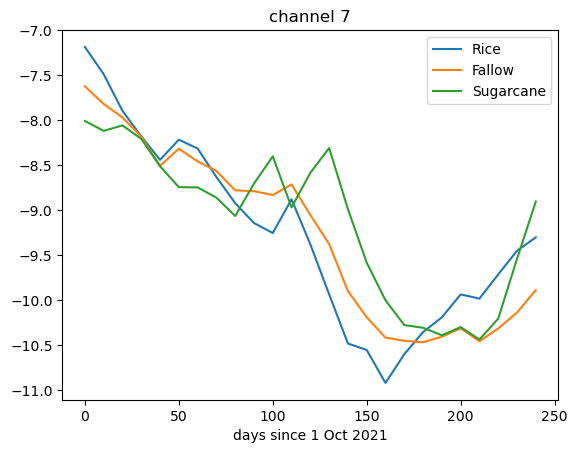

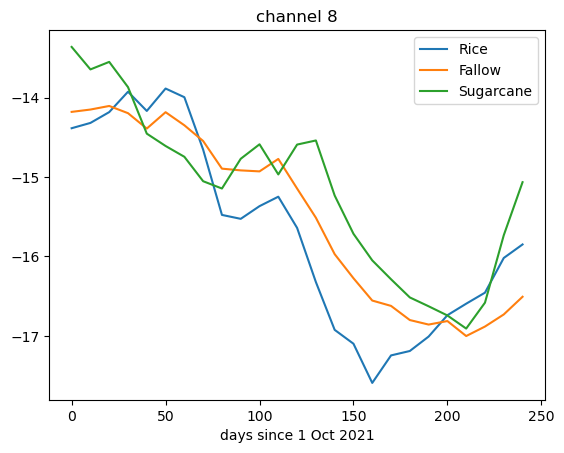

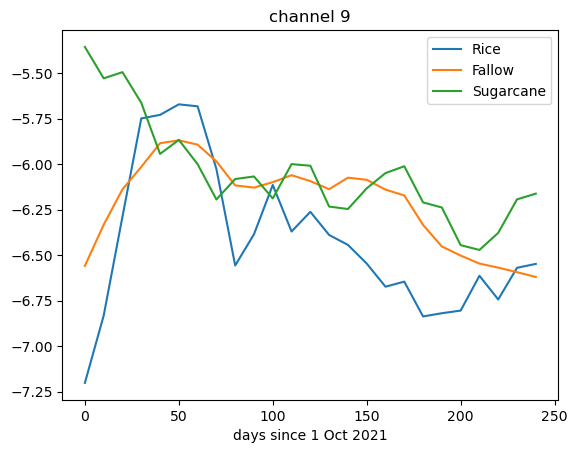

In [3]:
import matplotlib.pyplot as plt
GRID = np.arange(0, 243, 10)

# channels 7, 8 = the two Sentinel-1 bands, 9 = their difference (VH-VV style), per notebook 03
for ch in (7, 8, 9):
    for c in ["Rice", "Fallow", "Sugarcane"]:
        plt.plot(GRID, SEQ[y == CLASS_NAMES.index(c), :, ch].mean(0), label=c)
    plt.title(f"channel {ch}"); plt.legend(); plt.xlabel("days since 1 Oct 2021"); plt.show()

In [4]:
import json
kb = json.load(open("crop_knowledge.json"))
for name, e in kb.items():
    missing = [k for k, v in e.items() if v in (None, [], "")]
    print(f"{name:10s} missing: {missing}")

Wheat      missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Mustard    missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Lentil     missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Fallow     missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
GreenPea   missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Sugarcane  missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Garlic     missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Maize      missing: 

In [5]:
import json
kb = json.load(open("crop_knowledge.json"))

fill = {
  "Sugarcane": {
    "season": "long-duration (about 10-18 months; 12 is most common)",
    "sowing_months": "Autumn Oct-Nov; spring Feb-Mar; late spring Apr-May in western UP after wheat harvest; Bihar Jan-Feb (secondary source)",
    "peak_greenness_months": "From AgriFieldNet data: median NDVI peak day 10 (~mid Oct). Standing crop, so NDVI stays flat through the rabi window.",
    "harvest_months": None,
    "description": "Long-duration standing crop planted in autumn or spring. Autumn-planted cane grows slowly in winter and rapidly in spring.",
    "distinguishing_cues": "Flat NDVI like Fallow and Rice; radar (VV/VH) stays higher until about day 130 (early Feb) and then drops, unlike Fallow and Rice.",
    "sources": [
      {"title": "Indian Farming (ICAR) - sugarcane planting times", "url": "https://epubs.icar.org.in/index.php/IndFarm/article/download/105685/41413/273780"},
      {"title": "Sugarcane Production in India (seasons and duration)", "url": "https://vajiramandravi.com/current-affairs/?p=78073"},
      {"title": "Sugarcane farming guide (Bihar timing; secondary source)", "url": "https://www.agrifarming.in/sugarcane-farming-for-guide-beginners"}
    ]
  },
  "Potato": {
    "season": "rabi",
    "sowing_months": "Oct-Nov in the Indo-Gangetic plains; early crop 3rd week Sep to 1st week Oct, main crop Oct, late crop 3rd week Oct to 1st week Nov; planting limit about 5 Nov in the eastern plains (Bihar, Odisha, eastern UP)",
    "peak_greenness_months": "From AgriFieldNet data: median NDVI peak day 100 (~early Jan)",
    "harvest_months": "Jan-Feb (secondary source); Jan-Mar for some varieties",
    "description": "Cool-season tuber crop grown in the plains from autumn planting to late winter harvest.",
    "distinguishing_cues": "Earlier and lower NDVI peak than Wheat and Mustard (data: peak day about 100, amplitude about 0.42 vs 0.61 for Wheat).",
    "sources": [
      {"title": "Indian Farming (ICAR-CPRI) - planting limits by region", "url": "https://epubs.icar.org.in/index.php/IndFarm/article/download/151966/54635/414102"},
      {"title": "eAgri lecture notes - early/main/late crop dates", "url": "https://eagriorg.github.io/eagri50/AGRO301/pdf/lec24.pdf"},
      {"title": "PotatoPro Bihar (planting and harvest; secondary source)", "url": "https://www.potatopro.com/bihar/potato-statistics"}
    ]
  },
}
for crop, vals in fill.items():
    kb[crop].update(vals)
json.dump(kb, open("crop_knowledge.json", "w"), indent=2)
print(json.dumps(kb["Potato"], indent=2)[:600])

{
  "season": "rabi",
  "sowing_months": "Oct-Nov in the Indo-Gangetic plains; early crop 3rd week Sep to 1st week Oct, main crop Oct, late crop 3rd week Oct to 1st week Nov; planting limit about 5 Nov in the eastern plains (Bihar, Odisha, eastern UP)",
  "peak_greenness_months": "From AgriFieldNet data: median NDVI peak day 100 (~early Jan)",
  "harvest_months": "Jan-Feb (secondary source); Jan-Mar for some varieties",
  "description": "Cool-season tuber crop grown in the plains from autumn planting to late winter harvest.",
  "often_confused_with": [
    "Mustard",
    "Fallow"
  ],
  "disti


In [6]:
import json
kb = json.load(open("crop_knowledge.json"))

fill = {
  "Rice": {
    "season": "mainly kharif (Aman/Sali/Agahani winter rice, ~84% of rice); minor rabi/summer (Boro/Dalua/Garma) rice",
    "sowing_months": "Kharif: nursery Jun to 2nd week Jul (Odisha). Rabi/summer: sown Nov-Feb; Odisha dry-season nursery 15 Nov-15 Dec; Boro transplanted after 2nd week of Jan",
    "peak_greenness_months": "From AgriFieldNet data: median NDVI peak day 10 (~mid Oct), i.e. the tail of the kharif crop",
    "harvest_months": "Kharif: Oct-Dec (varies by variety and state). Rabi/summer: Mar-Jun",
    "description": "Dominant kharif crop in eastern India. Many fields are left fallow after the kharif harvest (rice-fallow), so the Oct-May window often shows little rice signal.",
    "distinguishing_cues": "NDVI is almost identical to Fallow in this window. Radar differs only slightly (VV dips deepest around day 160). Expect low confidence when Rice and Fallow are the top two candidates.",
    "sources": [
      {"title": "Rice in India: A Status Paper (seasons and harvest times)", "url": "https://drdpat.bih.nic.in/Status%20Paper%20-%2002.htm"},
      {"title": "ICAR-NRRI bulletin 222 (Odisha sowing windows)", "url": "https://icar-nrri.in/wp-content/uploads/2024/05/2-NRRI_CR-DHAN-324.pdf"},
      {"title": "Indian Journal of Agricultural Sciences - rice-fallow areas, eastern India", "url": "https://epubs.icar.org.in/index.php/IJAgS/article/download/88838/36354/227744"},
      {"title": "Indian Farming (ICAR) - Boro rice", "url": "https://epubs.icar.org.in/index.php/IndFarm/article/download/126451/49499/352762"}
    ]
  },
  "Garlic": {
    "season": "rabi",
    "sowing_months": "Mid-Oct to mid-Nov recommended (Oct-Nov across north India and Bihar; Sep-Nov quoted for the northern plains)",
    "peak_greenness_months": "From AgriFieldNet data: median NDVI peak day 130 (~early Feb)",
    "harvest_months": "Roughly Mar-Apr (derived from Oct-Nov planting plus a 4-5 month crop duration from a secondary source; not directly sourced)",
    "description": "Cool-season bulb crop planted in autumn and harvested when the tops start to yellow.",
    "distinguishing_cues": "NDVI peak timing is close to Wheat, Gram and Lentil (peak day 130 vs 140). Cannot be separated from them by NDVI timing alone.",
    "sources": [
      {"title": "Krishak Jagat - garlic planting window 15 Oct-15 Nov", "url": "https://www.en.krishakjagat.org/?p=41275"},
      {"title": "HORT 281 lecture notes - garlic planting by region", "url": "https://eagriorg.github.io/eagri50/HORT281/lec16.html"},
      {"title": "Garlic crop season and states (rabi Oct-Nov: Bihar, UP, others)", "url": "https://www.slideshare.net/slideshow/garlic-harvesting-curing-and-storage-technologytech/119470356"}
    ]
  },
}
for crop, vals in fill.items():
    kb[crop].update(vals)
json.dump(kb, open("crop_knowledge.json", "w"), indent=2)
for name, e in kb.items():
    print(f"{name:10s} missing:", [k for k, v in e.items() if v in (None, [], "")])

Wheat      missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Mustard    missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Lentil     missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Fallow     missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
GreenPea   missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Sugarcane  missing: ['harvest_months']
Garlic     missing: []
Maize      missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'description', 'distinguishing_cues', 'sources']
Gram       missing: ['season', 'sowing_months', 'peak_greenness_months', 'harvest_months', 'descri